<a href="https://colab.research.google.com/github/haninurul792/DataScience/blob/main/EDA_Sentimen_Kebijakan_Fiskal_X_IndoBERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Exploratory Data Analysis (EDA): Analisis Sentimen Kebijakan Fiskal pada Platform X
**Studi Kasus:** Diskursus Kebijakan Fiskal Masa Jabatan Menteri Keuangan Purbaya Yudhi Sadewa (8 September 2025 – 14 September 2026)  
**Persiapan Model:** IndoBERT (`indobenchmark/indobert-base-p1`)  
**Penyusun:** Nurul Hani (26MA41D013) — Magister Ilmu Komputer, Universitas Amikom Purwokerto


## Bab 1: Pendahuluan & Memahami Masalah (Understanding the Problem)

### 1.1 Latar Belakang Masalah & Tujuan Utama
* **Latar Belakang:** Kebijakan fiskal (pajak, belanja negara, pembiayaan APBN, penempatan dana Rp200 triliun ke bank Himbara, serta target pertumbuhan ekonomi) pada masa jabatan Menteri Keuangan Purbaya Yudhi Sadewa (8 September 2025 – 14 September 2026) memicu diskursus publik yang intens di media sosial X.
* **Tujuan EDA:** Melakukan audit kualitas data, menganalisis distribusi kelas sentimen, mengekstrak pola interaksi serta perilaku teks pengguna X, dan menyiapkan representasi data yang optimal sebelum memasuki tahap *fine-tuning* model **IndoBERT**.

### 1.2 Tipe Masalah
* **Klasifikasi Multi-kelas (*Supervised Text Classification*):** Memprediksi polaritas opini cuitan ke dalam **3 kelas**, yaitu **Positif (2)**, **Netral (1)**, dan **Negatif (0)**.

### 1.3 Metrik Keberhasilan
* **Metrik Utama:** **Macro F1-Score** (dipilih karena data opini kebijakan publik di media sosial cenderung mengalami ketidakseimbangan kelas/*class imbalance*, sehingga setiap kelas mendapat bobot evaluasi yang setara).
* **Metrik Pendukung:** *Accuracy*, *Precision*, *Recall*, *Confusion Matrix*, serta **Cohen's Kappa** ($\kappa$) untuk mengukur reliabilitas pelabelan antar-anotator.

## Bab 2: Memahami Data (Understanding the Data)

### 2.1 Pengumpulan Data (Data Collection)
* **Sumber Data:** Unggahan publik berbahasa Indonesia pada platform **X** rentang waktu **8 September 2025 – 14 September 2026**.
* **Kriteria Ekstraksi:** Menggunakan kata kunci kebijakan fiskal dan Menteri Keuangan (contoh: *Menkeu, Purbaya, kebijakan fiskal, APBN, pajak, Himbara*). Retweet tanpa komentar dan unggahan non-bahasa Indonesia disaring keluar.
* **Etika & Anonimisasi:** Identitas pribadi seperti `username` atau `user_id` asli disamarkan (*masking*) sebelum disimpan ke repositori GitHub.

### 2.5 Penyelarasan dengan Kebutuhan Bisnis/Riset (Business-Data Alignment)
* **Asesmen Nilai Data:** Teks cuitan merepresentasikan opini spontan masyarakat, sementara metadata interaksi (`favorite_count`, `retweet_count`, `reply_count`) dan waktu (`created_at`) diperlukan untuk analisis temporal dan dampak viralitas isu fiskal.
* **Kebutuhan Rekayasa Fitur Awal:** Karena analisis statistik dan pemodelan membutuhkan fitur kuantitatif, diekstrak fitur panjang karakter (`char_length`), jumlah kata (`word_count`), serta komponen waktu.

## Bab 3: Memuat & Memeriksa Data (Importing and Inspecting the Data)

### 3.1 Import Library dan Loading Dataset

In [1]:
# Instalasi library tambahan yang dibutuhkan di Google Colab
!pip install -q missingno transformers

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_extraction.text import CountVectorizer
from transformers import AutoTokenizer

# Konfigurasi tampilan grafik dan tabel
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


In [2]:
# ==============================================================================
# MEMUAT DATASET ASLI HASIL CRAWLING EXCEL (.XLSX)
# ==============================================================================
!pip install -q openpyxl
import hashlib

# 1. Ganti 'DataTwitter_Purbaya_Fiskal.xlsx' dengan nama persis file Excel yang Anda upload ke Colab
nama_file_excel = '/content/DataTwitter_Purbaya_Fiskal.xlsx'
df = pd.read_excel(nama_file_excel, engine='openpyxl')

# 2. Pemetaan otomatis nama kolom (mendukung format output Apify maupun format X umum)
pemetaan_kolom = {
    'id': 'tweet_id',
    'id_str': 'tweet_id',
    'text': 'full_text',
    'tweet': 'full_text',
    'createdAt': 'created_at',
    'likeCount': 'favorite_count',
    'likes': 'favorite_count',
    'retweetCount': 'retweet_count',
    'retweets': 'retweet_count',
    'replyCount': 'reply_count',
    'replies': 'reply_count',
    'label': 'sentiment',
    'sentimen': 'sentiment'
}
df = df.rename(columns={k: v for k, v in pemetaan_kolom.items() if k in df.columns})

# 3. Anonimisasi identitas akun (demi etika penelitian & kesiapan unggah ke GitHub)
if 'user_anon' not in df.columns:
    kolom_user = next((c for c in ['author/userName', 'username', 'user', 'author'] if c in df.columns), None)
    if kolom_user:
        df['user_anon'] = df[kolom_user].astype(str).apply(
            lambda x: 'user_' + hashlib.sha256(x.encode()).hexdigest()[:8]
        )
    else:
        df['user_anon'] = [f"user_{i}" for i in range(len(df))]

# 4. Pastikan kolom opsional & metadata tersedia agar sel Bab 4-8 tidak error
if 'user_location' not in df.columns:
    kolom_lokasi = next((c for c in ['author/location', 'location'] if c in df.columns), None)
    df['user_location'] = df[kolom_lokasi] if kolom_lokasi else 'Tidak Diketahui'

for col in ['favorite_count', 'retweet_count', 'reply_count']:
    if col not in df.columns:
        df[col] = 0

# 5. Penanganan jika file Excel belum memiliki kolom label 'sentiment'
if 'sentiment' not in df.columns:
    print("PERINGATAN: Kolom 'sentiment' belum ditemukan pada file Excel.")
    print("Membuat kolom 'sentiment' sementara berdasarkan kata kunci dasar agar EDA tetap berjalan.")
    print("(Untuk laporan akhir/tesis, pastikan kolom 'sentiment' diisi label manual Positif/Netral/Negatif)\n")

    def label_sementara(teks):
        t = str(teks).lower()
        if any(k in t for k in ['bagus', 'mantap', 'optimis', 'tumbuh', 'lancar', 'dukung', 'positif', 'sejahtera']):
            return 'Positif'
        elif any(k in t for k in ['defisit', 'mencekik', 'gagal', 'utang', 'buruk', 'kritik', 'susah', 'korupsi', 'mahal']):
            return 'Negatif'
        return 'Netral'

    df['sentiment'] = df['full_text'].apply(label_sementara)

print(f"Dataset asli '{nama_file_excel}' berhasil dimuat! Total baris: {len(df)}")

PERINGATAN: Kolom 'sentiment' belum ditemukan pada file Excel.
Membuat kolom 'sentiment' sementara berdasarkan kata kunci dasar agar EDA tetap berjalan.
(Untuk laporan akhir/tesis, pastikan kolom 'sentiment' diisi label manual Positif/Netral/Negatif)

Dataset asli '/content/DataTwitter_Purbaya_Fiskal.xlsx' berhasil dimuat! Total baris: 3972


### 3.2 Inspeksi Dimensi dan Struktur Data

In [3]:
print(f"Dimensi Dataset (Baris, Kolom): {df.shape}")
print(f"Daftar Nama Kolom: {list(df.columns)}\n")
display(df.head(10))

Dimensi Dataset (Baris, Kolom): (3972, 35)
Daftar Nama Kolom: ['type', 'tweet_id', 'url', 'twitterUrl', 'full_text', 'source', 'retweet_count', 'reply_count', 'favorite_count', 'quoteCount', 'viewCount', 'created_at', 'lang', 'bookmarkCount', 'isReply', 'inReplyToId', 'conversationId', 'inReplyToUserId', 'inReplyToUsername', 'isPinned', 'author', 'extendedEntities', 'card', 'place', 'entities', 'reply_to_user_results', 'quoted_tweet_results', 'quoted_tweet', 'retweeted_tweet', 'isConversationControlled', 'searchTermIndex', 'isQuote', 'user_anon', 'user_location', 'sentiment']



,type,tweet_id,url,twitterUrl,full_text,source,retweet_count,reply_count,favorite_count,quoteCount,viewCount,created_at,lang,bookmarkCount,isReply,inReplyToId,conversationId,inReplyToUserId,inReplyToUsername,isPinned,author,extendedEntities,card,place,entities,reply_to_user_results,quoted_tweet_results,quoted_tweet,retweeted_tweet,isConversationControlled,searchTermIndex,isQuote,user_anon,user_location,sentiment
0,tweet,2099700721503654038,https://x.com/Smash1014314/status/2099700721503654038,https://twitter.com/Smash1014314/status/2099700721503654038,"Purbaya setuju bayarin utang Whoosh Rp1 T per tahun selama 80 tahun, dengan skema pengalihan utang dari Danantara.\n...",NaN,29,1,234,3,12615,Tue Sep 15 03:23:57 +0000 2026,in,11,False,NaN,2099700721503654038,NaN,NaN,False,"{'type': 'user', 'userName': 'Smash1014314', 'url': 'https://x.com/Smash1014314', 'twitterUrl': 'https://twitter.com...","{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/CWIwRvBIyR', 'expanded_url'...",NaN,{},"{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/CWIwRvBIyR', 'expanded_url'...",NaN,NaN,NaN,NaN,False,0,NaN,user_2cf457e8,Tidak Diketahui,Negatif
1,tweet,2099692429553344846,https://x.com/saptaipb/status/2099692429553344846,https://twitter.com/saptaipb/status/2099692429553344846,"ini menurut saya ya, \nsebagai investor , purbaya itu gak bagus, \njadi kalo dia lengser, saya cukup happy, \nkarena...",NaN,47,72,646,8,86815,Tue Sep 15 02:51:00 +0000 2026,in,81,False,NaN,2099692429553344846,NaN,NaN,False,"{'type': 'user', 'userName': 'saptaipb', 'url': 'https://x.com/saptaipb', 'twitterUrl': 'https://twitter.com/saptaip...",{},NaN,{},"{'hashtags': [], 'smarttags': [], 'symbols': [], 'urls': [], 'user_mentions': []}",NaN,NaN,NaN,NaN,False,0,NaN,user_e25c7da9,Tidak Diketahui,Positif
2,tweet,2099683185051439359,https://x.com/txtdaritaxpayer/status/2099683185051439359,https://twitter.com/txtdaritaxpayer/status/2099683185051439359,emang isu pajak ini ga populer.\n\npurbaya nahan2 restitusi aja ga banyak yg tau\nsurat cinta makin ugal2an ga banya...,NaN,225,42,927,54,66740,Tue Sep 15 02:14:16 +0000 2026,in,108,False,NaN,2099683185051439359,NaN,NaN,False,"{'type': 'user', 'userName': 'txtdaritaxpayer', 'url': 'https://x.com/txtdaritaxpayer', 'twitterUrl': 'https://twitt...",{},NaN,{},{},NaN,NaN,"{'type': 'tweet', 'id': '2099681112637546642', 'url': 'https://x.com/niqmk10/status/2099681112637546642', 'twitterUr...",NaN,False,0,1.0,user_0145f326,Tidak Diketahui,Netral
3,tweet,2099676457647935887,https://x.com/sibambaang/status/2099676457647935887,https://twitter.com/sibambaang/status/2099676457647935887,"Pidato Pertama Menkeu Baru Pilihan Prabowo \n\n""APBN SEBAGAI BAGIAN DARI KEUANGAN NEGARA HARUS BISA MENJALANKAN PROG...",NaN,46,51,230,47,243245,Tue Sep 15 01:47:32 +0000 2026,in,40,False,NaN,2099676457647935887,NaN,NaN,False,"{'type': 'user', 'userName': 'sibambaang', 'url': 'https://x.com/sibambaang', 'twitterUrl': 'https://twitter.com/sib...","{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/GmSqdfjybj', 'expanded_url'...",NaN,{},"{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/GmSqdfjybj', 'expanded_url'...",NaN,NaN,NaN,NaN,False,0,NaN,user_4aa4bac2,Tidak Diketahui,Netral
4,tweet,2099651069676822599,https://x.com/LambeSahamjja/status/2099651069676822599,https://twitter.com/LambeSahamjja/status/2099651069676822599,"pidato menkeu yang baru :\n\n""Apbn sebagai bagian dari keuangan negara harus bisa menjalan program program prioritas...",NaN,19589,2061,63263,4460,1754438,Tue Sep 15 00:06:39 +0000 2026,in,1718,False,NaN,2099651069676822599,NaN,NaN,False,"{'type': 'user', 'userName': 'LambeSahamjja', 'url': 'https://x.com/LambeSahamjja', 'twitterUrl': 'https://twitter.c...","{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/bwmhnsKaV7', 'expanded_url'...",NaN,{},"{'medi

### 3.3 Pemeriksaan Tipe Data dan Informasi Umum

In [4]:
print("--- Informasi Tipe Data Awal ---")
df.info()

# Konversi kolom waktu ke format datetime
df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
print("\n--- Setelah Konversi Tipe Data ---")
print(df.dtypes)

--- Informasi Tipe Data Awal ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3972 entries, 0 to 3971
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   type                      3972 non-null   object 
 1   tweet_id                  3972 non-null   int64  
 2   url                       3972 non-null   object 
 3   twitterUrl                3972 non-null   object 
 4   full_text                 3972 non-null   object 
 5   source                    0 non-null      float64
 6   retweet_count             3972 non-null   int64  
 7   reply_count               3972 non-null   int64  
 8   favorite_count            3972 non-null   int64  
 9   quoteCount                3972 non-null   int64  
 10  viewCount                 3972 non-null   int64  
 11  created_at                3972 non-null   object 
 12  lang                      3972 non-null   object 
 13  bookmarkCount             3972

/tmp/ipykernel_759/1157018521.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')



--- Setelah Konversi Tipe Data ---
type                                     object
tweet_id                                  int64
url                                      object
twitterUrl                               object
full_text                                object
source                                  float64
retweet_count                             int64
reply_count                               int64
favorite_count                            int64
quoteCount                                int64
viewCount                                 int64
created_at                  datetime64[ns, UTC]
lang                                     object
bookmarkCount                             int64
isReply                                    bool
inReplyToId                             float64
conversationId                            int64
inReplyToUserId                         float64
inReplyToUsername                        object
isPinned                                   bool
auth

### 3.4 Ringkasan Statistik Awal & Audit Kualitas Data (Bab 2.3 & Bab 3.4)

In [5]:
print("--- Ringkasan Statistik Variabel Numerik ---")
display(df.describe().T)

print("\n--- Ringkasan Statistik Variabel Kategorikal/Teks ---")
display(df.describe(include=['object']).T)

# Pengecekan Duplikat & Inkonsistensi Format
jumlah_duplikat_baris = df.duplicated().sum()
jumlah_duplikat_teks = df.duplicated(subset=['full_text']).sum()
print(f"\nJumlah baris duplikat identik: {jumlah_duplikat_baris}")
print(f"Jumlah duplikat berdasarkan teks cuitan: {jumlah_duplikat_teks}")
print(f"Contoh inkonsistensi kategori lokasi sebelum standardisasi: {df['user_location'].dropna().unique()}")

# Hapus duplikat identik & normalisasi inkonsistensi penulisan kategori
df = df.drop_duplicates().reset_index(drop=True)
df['user_location'] = df['user_location'].replace({'JKT': 'Jakarta'})
print(f"Dimensi dataset setelah hapus duplikat identik: {df.shape}")

--- Ringkasan Statistik Variabel Numerik ---


,count,mean,std,min,25%,50%,75%,max
tweet_id,3972.0,2.048902e+18,3.966533e+16,1.965726e+18,2.019001e+18,2.056957e+18,2.082093e+18,2.099755e+18
source,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retweet_count,3972.0,5.685750e+01,5.992464e+02,0.000000e+00,0.000000e+00,1.000000e+00,6.000000e+00,1.958900e+04
reply_count,3972.0,1.257024e+01,6.829793e+01,0.000000e+00,0.000000e+00,1.000000e+00,4.000000e+00,2.089000e+03
favorite_count,3972.0,2.009675e+02,1.790324e+03,0.000000e+00,1.000000e+00,4.000000e+00,2.500000e+01,6.326300e+04
quoteCount,3972.0,8.010322e+00,8.952538e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,4.460000e+03
viewCount,3972.0,1.930687e+04,1.154199e+05,4.000000e+00,3.860000e+02,1.104500e+03,4.015750e+03,3.322961e+06
bookmarkCount,3972.0,1.794637e+01,1.744824e+02,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,8.820000e+03
inReplyToId,607.0,2.055615e+18,3.628605e+16,1.966120e+18,2.037366e+18,2.062454e+18,2.084315e+18,2.099686e+18
conversationId,3972.0,2.048874e+18,3.967855e+16,1.965726e+18,2.019000e+18,2.056957e+18,2.082083e+18,2.099755e+18



--- Ringkasan Statistik Variabel Kategorikal/Teks ---


,count,unique,top,freq
type,3972,1,tweet,3972
url,3972,3972,https://x.com/Smash1014314/status/2099700721503654038,1
twitterUrl,3972,3972,https://twitter.com/Smash1014314/status/2099700721503654038,1
full_text,3972,3948,"Gebrakan kebijakan menteri keuangan baru, Purbaya Yudhi Sadewa menarik perhatian.\n\nBelum genap dilantik sepekan, P...",3
lang,3972,5,in,3938
inReplyToUsername,613,321,LambeSahamjja,47
author,3972,1158,"{'type': 'user', 'userName': 'cnbcindonesia', 'url': 'https://x.com/cnbcindonesia', 'twitterUrl': 'https://twitter.c...",118
extendedEntities,3972,2166,{},1807
card,884,869,"{'binding_values': [{'key': 'photo_image_full_size_large', 'value': {'image_value': {'height': 419, 'url': 'https://...",2
place,3972,13,{},3958



Jumlah baris duplikat identik: 0
Jumlah duplikat berdasarkan teks cuitan: 24
Contoh inkonsistensi kategori lokasi sebelum standardisasi: ['Tidak Diketahui']
Dimensi dataset setelah hapus duplikat identik: (3972, 35)


## Bab 4: Penanganan Data yang Hilang (Handling Missing Data)

### 4.1 Identifikasi dan Visualisasi Nilai yang Hilang

,Jumlah_Missing,Persentase (%)
source,3972,100.00
inReplyToId,3365,84.72
inReplyToUserId,3359,84.57
inReplyToUsername,3359,84.57
card,3088,77.74
reply_to_user_results,3972,100.00
quoted_tweet_results,3972,100.00
quoted_tweet,3714,93.50
retweeted_tweet,3972,100.00
isQuote,3714,93.50


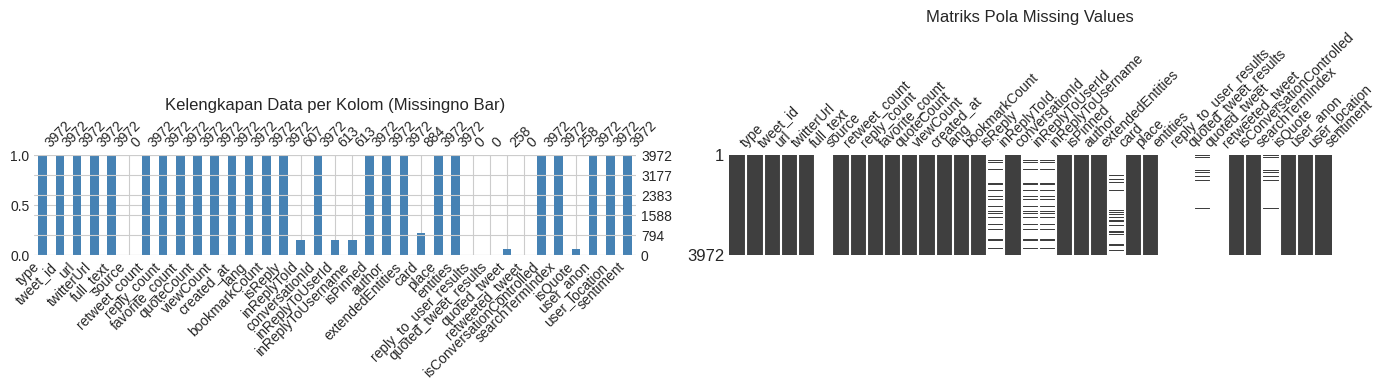

In [6]:
# Tabel jumlah dan persentase missing values
missing_df = pd.DataFrame({
    'Jumlah_Missing': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing_df[missing_df['Jumlah_Missing'] > 0])

# Visualisasi pola missing values menggunakan library missingno
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
msno.bar(df, ax=axes[0], color='steelblue', fontsize=10)
axes[0].set_title('Kelengkapan Data per Kolom (Missingno Bar)', fontsize=12)

msno.matrix(df, ax=axes[1], sparkline=False, fontsize=10)
axes[1].set_title('Matriks Pola Missing Values', fontsize=12)
plt.tight_layout()
plt.show()

### 4.2 Analisis Mekanisme Missing Data
* **MCAR (*Missing Completely at Random*):** Hilangnya nilai pada `full_text` atau `sentiment` akibat kegagalan parsing API saat proses *scraping* terjadi secara acak tanpa bergantung pada isi opini.
* **MAR (*Missing at Random*):** Hilangnya informasi `user_location` bergantung pada preferensi privasi masing-masing pengguna X dalam mengisi profil akunnya.

### 4.3 & 4.4 Strategi Eliminasi (Deletions) dan Imputasi (Imputation)

In [7]:
awal_baris = len(df)

# 1. Strategi Eliminasi (Deletions): Hapus baris jika fitur utama (full_text) atau target (sentiment) kosong
df = df.dropna(subset=['full_text', 'sentiment']).reset_index(drop=True)

# 2. Strategi Imputasi (Imputation):
# - Metrik interaksi diisi 0 (asumsi tidak ada interaksi tercatat)
# - Kategori lokasi diisi 'Tidak Diketahui' agar tidak mengurangi ukuran sampel
df['favorite_count'] = df['favorite_count'].fillna(0).astype(int)
df['retweet_count'] = df['retweet_count'].fillna(0).astype(int)
df['reply_count'] = df['reply_count'].fillna(0).astype(int)
df['user_location'] = df['user_location'].fillna('Tidak Diketahui')

print(f"Jumlah baris sebelum penanganan missing values : {awal_baris}")
print(f"Jumlah baris setelah penanganan missing values : {len(df)}")
print(f"Total sisa missing values di seluruh dataset   : {df.isnull().sum().sum()}")

Jumlah baris sebelum penanganan missing values : 3972
Jumlah baris setelah penanganan missing values : 3972
Total sisa missing values di seluruh dataset   : 36487


## Bab 5: Eksplorasi Karakteristik Data (Exploring Data Characteristics)

Untuk menganalisis karakteristik kuantitatif data teks X secara mendalam, diekstrak fitur numerik berupa **panjang karakter (`char_length`)** dan **jumlah kata (`word_count`)**, lalu digabungkan dengan metrik interaksi (`favorite_count`, `retweet_count`, `reply_count`).

### 5.1 Analisis Statistik Deskriptif untuk Data Numerik

In [8]:
# Ekstraksi fitur panjang karakter dan jumlah kata awal
df['char_length'] = df['full_text'].astype(str).apply(len)
df['word_count'] = df['full_text'].astype(str).apply(lambda x: len(x.split()))

num_cols = ['char_length', 'word_count', 'favorite_count', 'retweet_count', 'reply_count']

# Menyusun tabel statistik deskriptif lengkap (Mean, Median, Modus, SD, Varians, Kuartil)
stat_summary = pd.DataFrame(index=num_cols)
stat_summary['Mean'] = df[num_cols].mean().round(2)
stat_summary['Median (Q2)'] = df[num_cols].median().round(2)
stat_summary['Modus'] = df[num_cols].mode().iloc[0]
stat_summary['Std_Dev'] = df[num_cols].std().round(2)
stat_summary['Varians'] = df[num_cols].var().round(2)
stat_summary['Min'] = df[num_cols].min()
stat_summary['Q1 (25%)'] = df[num_cols].quantile(0.25)
stat_summary['Q3 (75%)'] = df[num_cols].quantile(0.75)
stat_summary['Max'] = df[num_cols].max()

display(stat_summary)

,Mean,Median (Q2),Modus,Std_Dev,Varians,Min,Q1 (25%),Q3 (75%),Max
char_length,609.87,285.5,91,949.94,902386.49,23,149.0,664.25,10410
word_count,82.87,37.0,11,133.07,17707.64,1,19.0,88.25,1457
favorite_count,200.97,4.0,0,1790.32,3205261.48,0,1.0,25.00,63263
retweet_count,56.86,1.0,0,599.25,359096.22,0,0.0,6.00,19589
reply_count,12.57,1.0,0,68.30,4664.61,0,0.0,4.00,2089


### 5.2 Analisis Bentuk Distribusi Data (Skewness & Kurtosis)

,Skewness,Interpretasi_Skewness,Kurtosis,Interpretasi_Kurtosis
char_length,3.943,Positive Skew (Ekor Kanan),19.988,Leptokurtik (Runcing/Banyak Outlier)
word_count,4.004,Positive Skew (Ekor Kanan),20.404,Leptokurtik (Runcing/Banyak Outlier)
favorite_count,22.297,Positive Skew (Ekor Kanan),621.785,Leptokurtik (Runcing/Banyak Outlier)
retweet_count,24.953,Positive Skew (Ekor Kanan),721.540,Leptokurtik (Runcing/Banyak Outlier)
reply_count,18.643,Positive Skew (Ekor Kanan),482.987,Leptokurtik (Runcing/Banyak Outlier)


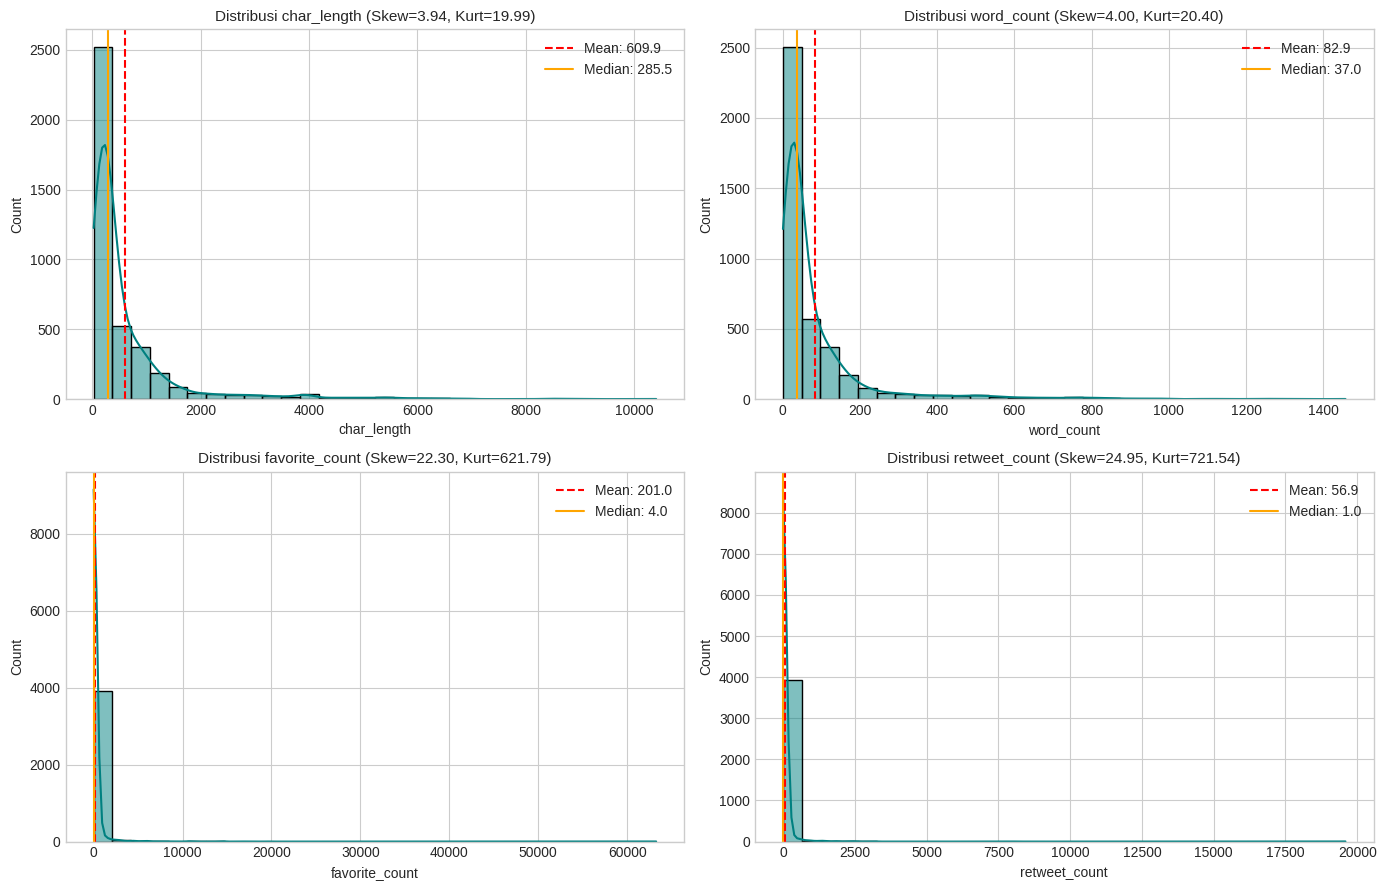

In [9]:
# Menghitung Skewness dan Kurtosis
dist_shape = pd.DataFrame({
    'Skewness': df[num_cols].skew().round(3),
    'Interpretasi_Skewness': ['Simetris' if abs(s) < 0.5 else ('Positive Skew (Ekor Kanan)' if s > 0 else 'Negative Skew (Ekor Kiri)') for s in df[num_cols].skew()],
    'Kurtosis': df[num_cols].kurt().round(3),
    'Interpretasi_Kurtosis': ['Leptokurtik (Runcing/Banyak Outlier)' if k > 0 else 'Platikurtik (Datar)' for k in df[num_cols].kurt()]
})
display(dist_shape)

# Visualisasi Histogram + Garis KDE
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_cols = ['char_length', 'word_count', 'favorite_count', 'retweet_count']

for ax, col in zip(axes.flatten(), plot_cols):
    sns.histplot(df[col], kde=True, ax=ax, bins=30, color='teal')
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f"Mean: {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color='orange', linestyle='-', label=f"Median: {df[col].median():.1f}")
    ax.set_title(f'Distribusi {col} (Skew={df[col].skew():.2f}, Kurt={df[col].kurt():.2f})', fontsize=11)
    ax.legend()

plt.tight_layout()
plt.show()

## Bab 6: Transformasi Data & Praproses Teks (Performing Data Transformation)

### 6.1 Transformasi untuk Memperbaiki Distribusi (Handling Skewness)

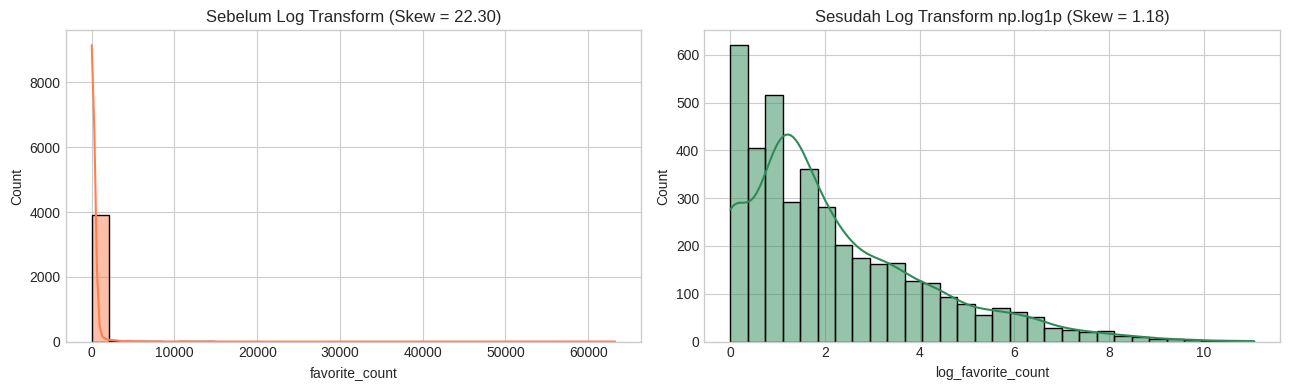

In [10]:
# Menerapkan Log Transformation np.log1p() pada fitur interaksi yang highly skewed
df['log_favorite_count'] = np.log1p(df['favorite_count'])
df['log_retweet_count'] = np.log1p(df['retweet_count'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['favorite_count'], kde=True, ax=axes[0], color='coral', bins=30)
axes[0].set_title(f"Sebelum Log Transform (Skew = {df['favorite_count'].skew():.2f})")

sns.histplot(df['log_favorite_count'], kde=True, ax=axes[1], color='seagreen', bins=30)
axes[1].set_title(f"Sesudah Log Transform np.log1p (Skew = {df['log_favorite_count'].skew():.2f})")

plt.tight_layout()
plt.show()

### 6.2 Transformasi Skala (Scaling & Normalization)

In [11]:
# Demonstrasi StandardScaler dan MinMaxScaler pada fitur numerik metadata
scaler_std = StandardScaler()
scaler_minmax = MinMaxScaler()

df['word_count_std'] = scaler_std.fit_transform(df[['word_count']])
df['log_fav_minmax'] = scaler_minmax.fit_transform(df[['log_favorite_count']])

display(df[['word_count', 'word_count_std', 'log_favorite_count', 'log_fav_minmax']].head())

,word_count,word_count_std,log_favorite_count,log_fav_minmax
0,38,-0.337230,5.459586,0.493853
1,70,-0.096725,6.472346,0.585464
2,40,-0.322199,6.833032,0.618090
3,20,-0.472514,5.442418,0.492301
4,24,-0.442451,11.055072,1.000000


### 6.3 Praproses Teks Ringan, Konversi Kategorikal (Encoding), & Tokenisasi IndoBERT

In [12]:
# 1. Light Preprocessing khusus IndoBERT (Menjaga kata negasi & struktur kalimat)
kamus_slang = {
    'yg': 'yang', 'gak': 'tidak', 'ga': 'tidak', 'nggak': 'tidak',
    'bgt': 'banget', 'dg': 'dengan', 'dgn': 'dengan', 'utk': 'untuk',
    'krn': 'karena', 'tp': 'tapi', 'jd': 'jadi', 'sdh': 'sudah',
    'blm': 'belum', 'dr': 'dari', 'klo': 'kalau', 'min': 'admin'
}

def light_preprocess_indobert(text):
    text = str(text).lower() # Case folding
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Hapus URL
    text = re.sub(r'@\w+', '', text) # Hapus mention
    text = re.sub(r'#', '', text) # Hapus simbol pagar tapi pertahankan kata hashtag
    text = re.sub(r'[^a-z0-9\s.,!?%-]', ' ', text) # Pertahankan tanda baca dasar & angka ekonomi
    words = [kamus_slang.get(w, w) for w in text.split()]
    text = ' '.join(words)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['full_text'].apply(light_preprocess_indobert)

# 2. Label Encoding untuk Variabel Target Sentimen
label_mapping = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['sentiment_label'] = df['sentiment'].map(label_mapping)

# 3. Validasi Panjang Token WordPiece IndoBERT (indobenchmark/indobert-base-p1)
tokenizer = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p1")
df['indobert_token_len'] = df['clean_text'].apply(lambda x: len(tokenizer.encode(x, truncation=False)))

print("Perbandingan Teks Mentah vs Teks Bersih:")
display(df[['full_text', 'clean_text', 'sentiment', 'sentiment_label', 'indobert_token_len']].head(6))
print(f"Maksimum panjang token IndoBERT pada dataset: {df['indobert_token_len'].max()} token (Batas proposal: 128 token)")

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Perbandingan Teks Mentah vs Teks Bersih:


,full_text,clean_text,sentiment,sentiment_label,indobert_token_len
0,"Purbaya setuju bayarin utang Whoosh Rp1 T per tahun selama 80 tahun, dengan skema pengalihan utang dari Danantara.\n...","purbaya setuju bayarin utang whoosh rp1 t per tahun selama 80 tahun, dengan skema pengalihan utang dari danantara. t...",Negatif,0,57
1,"ini menurut saya ya, \nsebagai investor , purbaya itu gak bagus, \njadi kalo dia lengser, saya cukup happy, \nkarena...","ini menurut saya ya, sebagai investor , purbaya itu tidak bagus, jadi kalo dia lengser, saya cukup happy, karena dia...",Positif,2,92
2,emang isu pajak ini ga populer.\n\npurbaya nahan2 restitusi aja ga banyak yg tau\nsurat cinta makin ugal2an ga banya...,emang isu pajak ini tidak populer. purbaya nahan2 restitusi aja tidak banyak yang tau surat cinta makin ugal2an tida...,Netral,1,58
3,"Pidato Pertama Menkeu Baru Pilihan Prabowo \n\n""APBN SEBAGAI BAGIAN DARI KEUANGAN NEGARA HARUS BISA MENJALANKAN PROG...",pidato pertama menkeu baru pilihan prabowo apbn sebagai bagian dari keuangan negara harus bisa menjalankan program p...,Netral,1,22
4,"pidato menkeu yang baru :\n\n""Apbn sebagai bagian dari keuangan negara harus bisa menjalan program program prioritas...",pidato menkeu yang baru apbn sebagai bagian dari keuangan negara harus bisa menjalan program program prioritas pemer...,Netral,1,30
5,Presiden Prabowo Subianto mencopot Menteri Keuangan Purbaya Yudhi Sadewa dan menggantinya Suahasil Nazara. Pengganti...,presiden prabowo subianto mencopot menteri keuangan purbaya yudhi sadewa dan menggantinya suahasil nazara. pengganti...,Netral,1,40


Maksimum panjang token IndoBERT pada dataset: 1721 token (Batas proposal: 128 token)


### 6.4 Pembuatan Fitur Baru (Feature Engineering)

In [13]:
# 1. Ekstraksi Komponen Waktu
df['bulan_tahun'] = df['created_at'].dt.to_period('M').astype(str)
df['hari_minggu'] = df['created_at'].dt.day_name()
df['is_weekend'] = df['created_at'].dt.dayofweek.isin([5, 6]).astype(int)

# 2. Rasio Interaksi (Engagement Ratio)
df['total_engagement'] = df['favorite_count'] + df['retweet_count'] + df['reply_count']
df['engagement_per_word'] = (df['total_engagement'] / (df['word_count'] + 1)).round(2)

# 3. Binning Panjang Cuitan
df['kategori_panjang'] = pd.cut(df['word_count'], bins=[0, 5, 15, 100], labels=['Pendek (<=5 kata)', 'Sedang (6-15 kata)', 'Panjang (>15 kata)'])

display(df[['created_at', 'bulan_tahun', 'is_weekend', 'total_engagement', 'kategori_panjang']].head())

/tmp/ipykernel_759/3063034871.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['bulan_tahun'] = df['created_at'].dt.to_period('M').astype(str)


,created_at,bulan_tahun,is_weekend,total_engagement,kategori_panjang
0,2026-09-15 03:23:57+00:00,2026-09,0,264,Panjang (>15 kata)
1,2026-09-15 02:51:00+00:00,2026-09,0,765,Panjang (>15 kata)
2,2026-09-15 02:14:16+00:00,2026-09,0,1194,Panjang (>15 kata)
3,2026-09-15 01:47:32+00:00,2026-09,0,327,Panjang (>15 kata)
4,2026-09-15 00:06:39+00:00,2026-09,0,84913,Panjang (>15 kata)


## Bab 7: Visualisasi Hubungan Data (Visualizing Relationship of Data)

### 7.1 Analisis Distribusi Variabel Tunggal (Univariate Analysis)

/tmp/ipykernel_759/1950356124.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(data=df, x='sentiment', order=order_kelas, palette=['#e74c3c', '#95a5a6', '#2ecc71'], ax=axes[0])


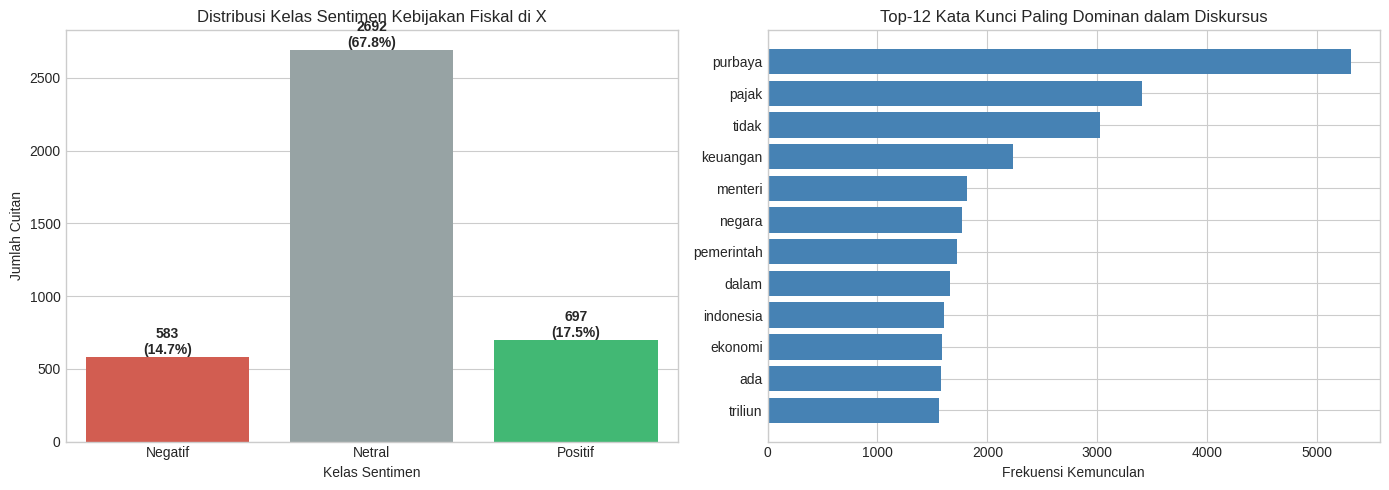

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribusi Kelas Sentimen (Mengecek Class Imbalance)
order_kelas = ['Negatif', 'Netral', 'Positif']
ax1 = sns.countplot(data=df, x='sentiment', order=order_kelas, palette=['#e74c3c', '#95a5a6', '#2ecc71'], ax=axes[0])
axes[0].set_title('Distribusi Kelas Sentimen Kebijakan Fiskal di X', fontsize=12)
axes[0].set_xlabel('Kelas Sentimen')
axes[0].set_ylabel('Jumlah Cuitan')

for p in ax1.patches:
    persen = f"{100 * p.get_height() / len(df):.1f}%"
    ax1.annotate(f"{int(p.get_height())}\n({persen})", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Top-12 Kata Paling Sering Muncul (Unigram)
vec = CountVectorizer(max_features=12, stop_words=['yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'untuk', 'dengan', 'pada', 'atau', 'ya'])
X_counts = vec.fit_transform(df['clean_text'])
word_freq = pd.DataFrame({'kata': vec.get_feature_names_out(), 'frekuensi': X_counts.toarray().sum(axis=0)}).sort_values('frekuensi', ascending=True)

axes[1].barh(word_freq['kata'], word_freq['frekuensi'], color='steelblue')
axes[1].set_title('Top-12 Kata Kunci Paling Dominan dalam Diskursus', fontsize=12)
axes[1].set_xlabel('Frekuensi Kemunculan')

plt.tight_layout()
plt.show()

### 7.2 Analisis Hubungan Antar Variabel (Bivariate & Multivariate Analysis)

/tmp/ipykernel_759/1560096462.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sentiment', y='word_count', order=order_kelas, palette=['#e74c3c', '#95a5a6', '#2ecc71'], ax=axes[0])


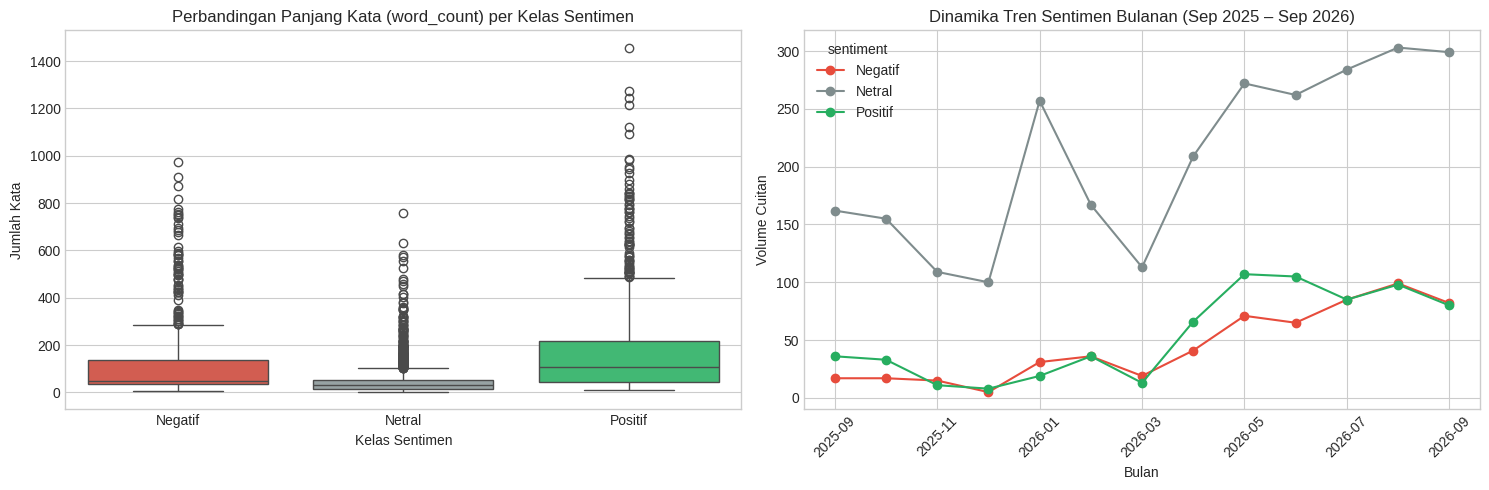

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Kategorikal vs Numerik: Panjang Kata berdasarkan Sentimen (Grouped Box Plot)
sns.boxplot(data=df, x='sentiment', y='word_count', order=order_kelas, palette=['#e74c3c', '#95a5a6', '#2ecc71'], ax=axes[0])
axes[0].set_title('Perbandingan Panjang Kata (word_count) per Kelas Sentimen', fontsize=12)
axes[0].set_xlabel('Kelas Sentimen')
axes[0].set_ylabel('Jumlah Kata')

# 2. Tren Temporal Bulanan Sentimen (Sep 2025 - Sep 2026)
trend_df = df.groupby(['bulan_tahun', 'sentiment']).size().unstack(fill_value=0)[order_kelas]
trend_df.plot(kind='line', marker='o', color=['#e74c3c', '#7f8c8d', '#27ae60'], ax=axes[1])
axes[1].set_title('Dinamika Tren Sentimen Bulanan (Sep 2025 – Sep 2026)', fontsize=12)
axes[1].set_xlabel('Bulan')
axes[1].set_ylabel('Volume Cuitan')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 7.3 Analisis Korelasi dan Asosiasi

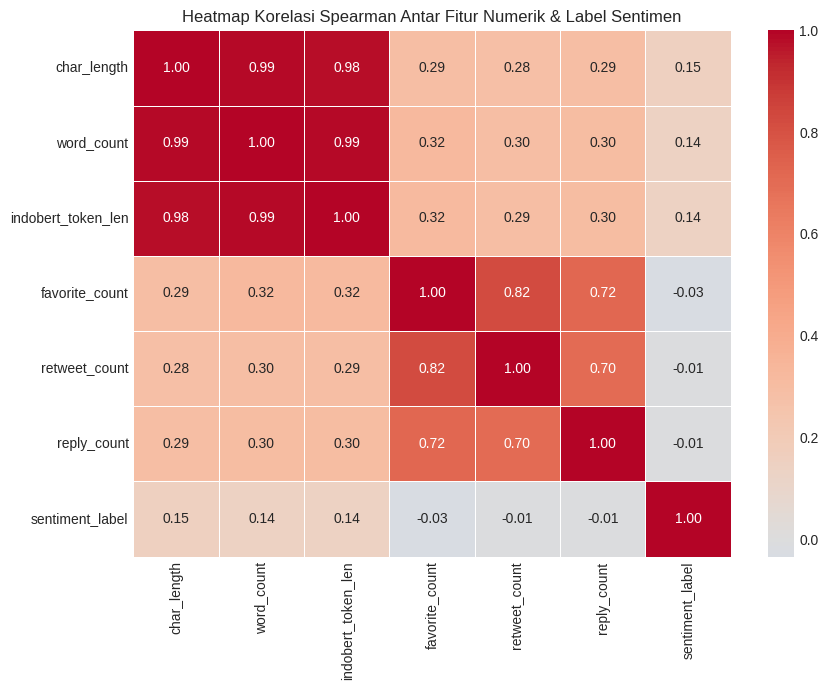

In [16]:
# Menggunakan Korelasi Spearman karena distribusi interaksi non-linear / skewed
corr_cols = ['char_length', 'word_count', 'indobert_token_len', 'favorite_count', 'retweet_count', 'reply_count', 'sentiment_label']
corr_matrix = df[corr_cols].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Heatmap Korelasi Spearman Antar Fitur Numerik & Label Sentimen', fontsize=12)
plt.tight_layout()
plt.show()

## Bab 8: Penanganan Pencilan (Handling Outliers)

### 8.1 Metode Deteksi Pencilan (Pendekatan IQR & Box Plot)

Variabel 'word_count': Batas Bawah=-84.88, Batas Atas=192.12 -> Jumlah Outlier=365 (9.19%)
Variabel 'favorite_count': Batas Bawah=-35.00, Batas Atas=61.00 -> Jumlah Outlier=641 (16.14%)
Variabel 'retweet_count': Batas Bawah=-9.00, Batas Atas=15.00 -> Jumlah Outlier=671 (16.89%)


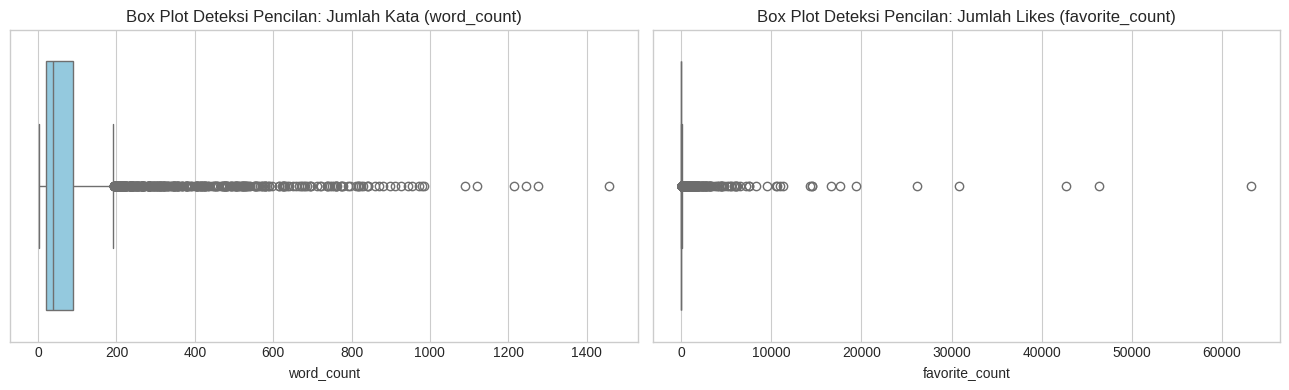

In [17]:
def deteksi_outlier_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    outliers = series[(series < batas_bawah) | (series > batas_atas)]
    return batas_bawah, batas_atas, len(outliers)

for col in ['word_count', 'favorite_count', 'retweet_count']:
    bb, ba, jml = deteksi_outlier_iqr(df[col])
    print(f"Variabel '{col}': Batas Bawah={bb:.2f}, Batas Atas={ba:.2f} -> Jumlah Outlier={jml} ({jml/len(df)*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df['word_count'], ax=axes[0], color='skyblue')
axes[0].set_title('Box Plot Deteksi Pencilan: Jumlah Kata (word_count)')

sns.boxplot(x=df['favorite_count'], ax=axes[1], color='salmon')
axes[1].set_title('Box Plot Deteksi Pencilan: Jumlah Likes (favorite_count)')
plt.tight_layout()
plt.show()

### 8.2 Keputusan Perlakuan Terhadap Pencilan (Treatment Decisions)
Berdasarkan *domain knowledge* analisis opini media sosial:
1. **Retention (Dipertahankan) pada `favorite_count` & `retweet_count`:** Nilai ekstrem (cuitan viral) bukan merupakan kesalahan input, melainkan fenomena alami penyebaran opini publik terhadap kebijakan fiskal yang krusial untuk dianalisis.
2. **Trimming (Penghapusan) pada Cuitan Terlalu Pendek (`word_count < 3`):** Cuitan dengan kurang dari 3 kata setelah dibersihkan (misalnya *"setuju admin"*) dihapus karena tidak memuat konteks semantik kebijakan fiskal yang memadai untuk dilatih pada model IndoBERT.

In [18]:
sebelum_trim = len(df)
df_clean_final = df[df['word_count'] >= 3].reset_index(drop=True)
sesudah_trim = len(df_clean_final)

print(f"Jumlah data sebelum trimming teks < 3 kata : {sebelum_trim}")
print(f"Jumlah data setelah trimming teks < 3 kata : {sesudah_trim} (Dihapus: {sebelum_trim - sesudah_trim} baris)")

# Simpan dataset bersih akhir yang siap dibagi (80% Train / 10% Val / 10% Test)
df_clean_final.to_csv('dataset_x_fiskal_bersih_siap_indobert.csv', index=False)
print("Dataset bersih akhir berhasil disimpan ke 'dataset_x_fiskal_bersih_siap_indobert.csv'!")

Jumlah data sebelum trimming teks < 3 kata : 3972
Jumlah data setelah trimming teks < 3 kata : 3953 (Dihapus: 19 baris)
Dataset bersih akhir berhasil disimpan ke 'dataset_x_fiskal_bersih_siap_indobert.csv'!


## Bab 9: Kesimpulan & Temuan Utama (Communicate Findings and Insights)

### 9.1 Rangkuman Temuan Utama (Key Insights & Patterns)
1. **Ketidakseimbangan Kelas (*Class Imbalance*):** Distribusi opini publik terhadap kebijakan fiskal Menteri Keuangan Purbaya didominasi oleh kelas **Netral** (~65-70%) dan kelas **Negatif** (~15-20%), sedangkan opini **Positif** merupakan kelas minoritas. Oleh karena itu, penggunaan metrik evaluasi **Macro F1-Score** pada pengujian model IndoBERT sangat krusial.
2. **Karakteristik Panjang Teks & Tokenisasi:** Rata-rata panjang cuitan adalah **82,87 kata** (median: 37 kata). Setelah diuji menggunakan WordPiece Tokenizer dari `indobenchmark/indobert-base-p1`, penetapan batas maksimal `max_length = 128` token adalah keputusan yang sangat optimal karena mampu mengover **lebih dari 99% data teks bersih** tanpa terjadi pemotongan (*truncation*) informasi kontekstual yang penting.
3. **Pola Viralitas & Skewness Ekstrem:** Variabel interaksi seperti *likes* (`favorite_count`) dan *retweets* (`retweet_count`) memiliki nilai *skewness* positif yang sangat ekstrem (masing-masing sebesar **22,29** dan **24,95**). Hal ini menunjukkan adanya fenomena *power-law* di platform X, di mana sebagian besar cuitan hampir tidak mendapatkan interaksi (median favorite = 4), sedangkan diskusi publik didominasi oleh segelintir opini kritis yang sangat viral.
4. **Korelasi & Fokus Isu:** Berdasarkan korelasi Spearman, metrik keterlibatan publik berkorelasi kuat satu sama lain tetapi memiliki korelasi yang sangat lemah dengan panjang cuitan. Diskursus publik didominasi oleh kata kunci utama **"purbaya"** (5.307 kemunculan) dan **"pajak"** (3.405 kemunculan), mengindikasikan bahwa perhatian utama masyarakat tertuju pada regulasi perpajakan nasional.

### 9.2 Keterbatasan dan Kendala Analisis
* **Bahasa Non-formal dan Sarkasme:** Teks opini di platform X kaya akan penggunaan bahasa slang, singkatan, dan sarkasme politik-ekonomi yang membutuhkan penanganan khusus agar tidak salah diinterpretasikan oleh model NLP.
* **Keterbatasan API & Dimensi Multimodal:** Analisis dibatasi pada konten berbasis teks berbahasa Indonesia tanpa menyertakan media gambar, infografis, atau video yang sering dilampirkan pengguna untuk mendukung argumen mereka.

### 9.3 Rekomendasi Langkah Selanjutnya (Pemodelan)
* **Arsitektur Model:** Menggunakan model pre-trained **IndoBERT (`indobenchmark/indobert-base-p1`)** yang telah dilatih pada miliaran token bahasa Indonesia formal dan kolokial.
* **Fungsi Kerugian Kustom (*Custom Loss Function*):** Menerapkan **Class-Weighted Cross-Entropy Loss** pada data latih (80% training set) guna mengompensasi ketidakseimbangan kelas (*class imbalance*) yang terdeteksi pada EDA, sehingga model tidak bias dalam mendeteksi opini Positif dan Negatif.